# Demonstration Notebook
This notebook demonstrates and compares three ABSA implementations:
1. Lexicon-Based ABSA (spaCy + Sentiment Lexicon)
2. Transformer-Based ABSA (Pretrained Transformer Model)
3. LLM-Based ABSA using Ollama (Local LLM)

**The goal is to:**
- Run all three models on sample review data
- Compare their outputs on identical inputs
- Measure accuracy and runtime
- Analyze strengths, weaknesses, and trade-offs

**Code Reference**: The Code was generated with the help of ChatGpt

In [1]:
import time
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# Import your implementations
from absa.lexicon_absa import LexiconABSA, LexiconABSAConfig
from absa.llm_absa import LLMABSA
from absa.transformer_absa import TransformerABSA, TransformerABSAConfig
from absa.base import AspectSentiment


In [2]:
# ==============================================================================
# 1. LOAD YELP DATASET
# ==============================================================================

def load_yelp_data(filepath: str, sample_size: int = 50) -> pd.DataFrame:
    """Load Yelp reviews from JSONL file."""
    reviews = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            reviews.append(json.loads(line))
            if len(reviews) >= sample_size:
                break

    df = pd.DataFrame(reviews)
    df['review_id'] = range(1, len(df) + 1)
    return df

YELP_FILE = "../data/yelp_sample_20k.json"
SAMPLE_SIZE = 20  # Number of reviews to analyze

print("=" * 80)
print("LOADING YELP DATASET")
print("=" * 80)

try:
    df = load_yelp_data(YELP_FILE, SAMPLE_SIZE)
    print(f"Loaded {len(df)} reviews")
    print(f"\nStar rating distribution:")
    print(df['stars'].value_counts().sort_index())
    print(f"\nAverage review length: {df['text'].str.len().mean():.0f} characters")
except FileNotFoundError:
    print(f"File not found: {YELP_FILE}")
    print("\nUsing sample reviews instead...\n")

    # Fallback sample data in Yelp format
    sample_data = [
        {"text": "food was good. coffee was just ok. Service was slow.... we did have a large party but it was like they were doing each cup of coffee and getting each dessert one at a time, and serving us so slowly half the crowd was done before some got their first cup of coffee or anything to eat. not well organized at all.", "stars": 3.0},
        {"text": "My wife & I had a very enjoyable first visit to Bici this evening (Saturday). Very friendly and knowledgeable staff, casual but stylish decor, no kids present but there were kids items on the menu (so I guess we were in the right place at the right time!). Food was very good overall and we especially liked the Tuna Nicoise and Mushroom Ragu over Polenta. Chicken Picata was ok but too oily or buttery. The 3-huumus selection was also very good. \n\nI'm sure we'll be back and would recommend it highly. On this night the friendly staff made the experience extra nice.", "stars": 4.0},
        {"text": "Healthiest lunch option in the Cool Springs area by far. Sure there are other places that offer a good salad, but Grabbagreen really makes sure you can't get distracted by the add ons (like that extra brownie for dessert). I ordered the Gulf of Mexico bowl with chicken instead of shrimp. Everything was fresh and great quality, but overall kind of bland. The avocado dressing just tasted like a pureed avocado, which isn't necessarily a bad thing, but if you're looking for a flavor punch that dressing will not suffice. If you get chicken, it's ground meat instead of chopped--just FYI in case you don't realize it when you order. I think the ground chicken definitely makes the bowl look more like that classic clean \"meal prep\" lunch. I'm sure there are other bowls with dressings that are far more tasty. I mean, they even have a healthy mac and cheese. But when I come here it's either the intention to go all the way and eat as many greens as possible. \n\nAs others have said, Grabbagreen is a great option if you're really trying to stick to a healthy eating habit. Or if you're like me, you eat here when you feel really guilty for eating a bunch of junk days before. There are quick grab-and-go items available and fresh made juices and smoothies, so it's a great option to add to your Cool Springs lunch rotation.", "stars": 4.0},
        {"text": "Nice and friendly staff, decent food and a fun environment. \n\nMost everyone has tried hibachi before and this one is a nice option and top 3 choice in the game.\n\nI can never wear the same outfit again before washing due to the lingering smell of hibachi and there are usually leftovers with rice and noodles. \n\nStop by and give it a shot if you never have and make sure to sign up for the birthday club free meal.", "stars": 3.0},
        {"text": "Amazing food. Ridiculously high quality ingredients. Definitely will come back whenever I get a chance.", "stars": 5.0},
        {"text": "The mushroom risotto was perfection, but the service was slow. The atmosphere was cozy and the chocolate cake divine.", "stars": 4.0},
        {"text": "Terrible experience. The food was cold, the staff was rude, and the restaurant was dirty. Never coming back.", "stars": 1.0},
        {"text": "Love this place! The tacos are authentic and flavorful. The salsa bar is fantastic. Staff is always welcoming.", "stars": 5.0},
    ]
    df = pd.DataFrame(sample_data)
    df['review_id'] = range(1, len(df) + 1)


LOADING YELP DATASET
Loaded 20 reviews

Star rating distribution:
stars
2.0    3
3.0    3
4.0    5
5.0    9
Name: count, dtype: int64

Average review length: 527 characters


In [3]:
# ==============================================================================
# 2. INITIALIZE MODELS
# ==============================================================================

print("\n" + "=" * 80)
print("INITIALIZING ABSA MODELS")
print("=" * 80)

models = {}

print("\n[1/3] Loading Lexicon-Based Model...")
try:
    models['lexicon'] = LexiconABSA(LexiconABSAConfig())
    print("Lexicon model loaded successfully")
except Exception as e:
    print(f"Failed to load Lexicon model: {e}")
    models['lexicon'] = None

print("\n[2/3] Loading LLM-Based Model...")
try:
    models['llm'] = LLMABSA(model_name="llama3", max_aspects=8)
    print("LLM model loaded successfully")
except Exception as e:
    print(f"Failed to load LLM model: {e}")
    print("Note: Make sure Ollama is running with 'ollama serve' and llama3 is pulled")
    models['llm'] = None

print("\n[3/3] Loading Transformer-Based Model...")
try:
    models['transformer'] = TransformerABSA(TransformerABSAConfig())
    print("Transformer model loaded successfully")
except Exception as e:
    print(f"Failed to load Transformer model: {e}")
    models['transformer'] = None

active_models = [name for name, model in models.items() if model is not None]
print(f"\n{len(active_models)} models active: {', '.join(active_models)}")



INITIALIZING ABSA MODELS

[1/3] Loading Lexicon-Based Model...
Lexicon model loaded successfully

[2/3] Loading LLM-Based Model...
LLMABSA initialized with model: llama3
LLM model loaded successfully

[3/3] Loading Transformer-Based Model...


Device set to use cpu


Transformer model loaded successfully

3 models active: lexicon, llm, transformer


In [4]:
# ==============================================================================
# 3. RUN PREDICTIONS
# ==============================================================================

def run_predictions(model, review_text: str, model_name: str) -> tuple:
    """Run prediction and measure time."""
    if model is None:
        return [], 0.0

    start = time.time()
    try:
        results = model.analyze(review_text)
        elapsed = time.time() - start
        return results, elapsed
    except Exception as e:
        print(f"Error with {model_name}: {e}")
        return [], 0.0

print("\n" + "=" * 80)
print("RUNNING PREDICTIONS")
print("=" * 80)

all_results = defaultdict(list)
performance_data = defaultdict(list)

for idx, row in df.iterrows():
    review_id = row['review_id']
    text = row['text']
    stars = row['stars']

    print(f"\n[{idx+1}/{len(df)}] Review {review_id} ({stars:.1f})")
    print(f"Text: {text[:100]}{'...' if len(text) > 100 else ''}")

    for model_name, model in models.items():
        if model is None:
            continue

        results, elapsed = run_predictions(model, text, model_name)

        all_results[model_name].append({
            'review_id': review_id,
            'text': text,
            'stars': stars,
            'predictions': results,
            'time': elapsed
        })

        performance_data[model_name].append(elapsed)

        print(f"  {model_name:>12}: {len(results):2d} aspects in {elapsed:.3f}s")

print("\nPredictions complete")


RUNNING PREDICTIONS

[1/20] Review 1 (5.0)
Text: Fresh spring water... check!
Hugely portioned (although on the menu it said regular sized) cobb sala...
       lexicon:  2 aspects in 0.014s


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


           llm:  5 aspects in 90.355s
   transformer:  6 aspects in 5.908s

[2/20] Review 2 (4.0)
Text: I tried their decaf latte which was tasty, foamy, so good and light that I didn't need to add sugar....
       lexicon:  2 aspects in 0.021s
           llm:  4 aspects in 27.737s
   transformer:  5 aspects in 1.096s

[3/20] Review 3 (5.0)
Text: Amazing Bagels!! My favorite place ever! Super fast cook and donuts are fresh and they taste so good...
       lexicon:  2 aspects in 0.000s
           llm:  2 aspects in 14.192s
   transformer:  2 aspects in 0.465s

[4/20] Review 4 (5.0)
Text: Well, I visited UAL for the first time today because I wanted to see what the big deal was about.  M...
       lexicon:  7 aspects in 0.032s
           llm:  4 aspects in 47.275s
   transformer:  4 aspects in 1.787s

[5/20] Review 5 (4.0)
Text: Eight of us came here for brunch for my birthday. We made a reservation and were seated quickly. We ...
       lexicon:  4 aspects in 0.023s
           llm:  5 a

In [13]:
# ==============================================================================
# 4. QUALITATIVE COMPARISON
# ==============================================================================

def print_detailed_comparison(review_idx: int):
    """Print detailed side-by-side comparison for a specific review in tabular format."""
    print("\n" + "=" * 80)
    print(f"DETAILED COMPARISON - Review #{review_idx + 1}")
    print("=" * 80)

    row = df.iloc[review_idx]
    print(f"\nStar Rating: {row['stars']:.1f}")
    print(f"\nReview Text:\n{row['text']}\n")

    # Collect all predictions in a table format
    table_data = []
    for model_name in active_models:
        result = all_results[model_name][review_idx]
        if result['predictions']:
            for pred in result['predictions']:
                table_data.append({
                    'Model': model_name,
                    'Aspect': pred.aspect,
                    'Sentiment': pred.sentiment,
                    'Confidence': pred.confidence
                })
        else:
            table_data.append({
                'Model': model_name,
                'Aspect': '(no aspects detected)',
                'Sentiment': '-',
                'Confidence': 0.0
            })

    if table_data:
        # Create DataFrame for nice formatting
        comparison_df = pd.DataFrame(table_data)

        # Sort by model then confidence
        comparison_df['model_order'] = comparison_df['Model'].map(
            {m: i for i, m in enumerate(active_models)}
        )
        comparison_df = comparison_df.sort_values(['model_order', 'Confidence'], ascending=[True, False])
        comparison_df = comparison_df.drop('model_order', axis=1)

        print("\n" + "-" * 80)
        print(f"{'Model':<20} {'Aspect':<30} {'Sentiment':<15} {'Confidence':<10}")
        print("-" * 80)

        for _, row_data in comparison_df.iterrows():
            model = row_data['Model']
            aspect = row_data['Aspect'][:28]  # Truncate if too long
            sentiment = row_data['Sentiment']
            confidence = row_data['Confidence']

            print(f"{model:<20} {aspect:<30} {sentiment:<13} {confidence:>6.2f}")

        print("-" * 80)

        # Print timing info
        print("\nProcessing Time:")
        for model_name in active_models:
            result = all_results[model_name][review_idx]
            print(f"  {model_name:<15}: {result['time']:.3f}s")
    else:
        print("\n(No predictions from any model)")

# Show first 3 reviews in detail
print("\n" + "=" * 80)
print("QUALITATIVE ANALYSIS - Sample Reviews")
print("=" * 80)

for i in range(min(3, len(df))):
    print_detailed_comparison(i)


QUALITATIVE ANALYSIS - Sample Reviews

DETAILED COMPARISON - Review #1

Star Rating: 5.0

Review Text:
Fresh spring water... check!
Hugely portioned (although on the menu it said regular sized) cobb salad... check!
Cheap prices... check!

During my short stay at Reno, one of my friends checked this place out, came back to the hotel, and urged all of us to come eat here. The food was great. 

If I ever end up back in Reno, I will definitely come back here. I really want to try their "nookie" for breakfast.


--------------------------------------------------------------------------------
Model                Aspect                         Sentiment       Confidence
--------------------------------------------------------------------------------
lexicon              food                           positive        0.46
lexicon              fresh spring water             positive        0.42
llm                  spring water                   positive        0.90
llm                  food 

In [17]:
# ==============================================================================
# 5. STATISTICS
# ==============================================================================

stats = {}
stats_rows = []

for model_name in active_models:
    all_aspects = []
    all_sentiments = []
    all_confidences = []

    for result in all_results[model_name]:
        for pred in result['predictions']:
            all_aspects.append(pred.aspect.lower())
            all_sentiments.append(pred.sentiment)
            all_confidences.append(pred.confidence)

    sentiment_dist = Counter(all_sentiments)
    total_aspects = len(all_aspects)

    # Store detailed stats for later use
    stats[model_name] = {
        'total_aspects': total_aspects,
        'unique_aspects': len(set(all_aspects)),
        'avg_aspects_per_review': len(all_aspects) / len(df) if len(df) > 0 else 0,
        'sentiment_dist': sentiment_dist,
        'avg_confidence': np.mean(all_confidences) if all_confidences else 0,
        'top_aspects': Counter(all_aspects).most_common(10),
        'avg_time': np.mean(performance_data[model_name]),
        'total_time': sum(performance_data[model_name])
    }

    # Create row for summary DataFrame
    stats_rows.append({
        'Model': model_name,
        'Total Aspects': total_aspects,
        'Unique Aspects': len(set(all_aspects)),
        'Aspects/Review': f"{len(all_aspects) / len(df):.2f}" if len(df) > 0 else "0.00",
        'Positive': sentiment_dist.get('positive', 0),
        'Positive %': f"{sentiment_dist.get('positive', 0) / total_aspects * 100:.1f}%" if total_aspects > 0 else "0.0%",
        'Negative': sentiment_dist.get('negative', 0),
        'Negative %': f"{sentiment_dist.get('negative', 0) / total_aspects * 100:.1f}%" if total_aspects > 0 else "0.0%",
        'Neutral': sentiment_dist.get('neutral', 0),
        'Neutral %': f"{sentiment_dist.get('neutral', 0) / total_aspects * 100:.1f}%" if total_aspects > 0 else "0.0%",
        'Avg Confidence': f"{np.mean(all_confidences):.3f}" if all_confidences else "0.000",
        'Avg Time (s)': f"{np.mean(performance_data[model_name]):.3f}",
        'Total Time (s)': f"{sum(performance_data[model_name]):.2f}",
        'Throughput (rev/s)': f"{1/np.mean(performance_data[model_name]):.2f}" if np.mean(performance_data[model_name]) > 0 else "0.00"
    })

# Create and display summary DataFrame
stats_df = pd.DataFrame(stats_rows)
print("\n" + "=" * 80)
print("SUMMARY STATISTICS TABLE")
print("=" * 80)
stats_df



SUMMARY STATISTICS TABLE


,Model,Total Aspects,Unique Aspects,Aspects/Review,Positive,Positive %,Negative,Negative %,Neutral,Neutral %,Avg Confidence,Avg Time (s),Total Time (s),Throughput (rev/s)
0,lexicon,89,74,4.45,84,94.4%,5,5.6%,0,0.0%,0.416,0.023,0.46,43.34
1,llm,97,76,4.85,74,76.3%,15,15.5%,8,8.2%,0.813,45.253,905.06,0.02
2,transformer,113,82,5.65,86,76.1%,13,11.5%,14,12.4%,0.910,2.323,46.47,0.43


In [10]:
# ==============================================================================
# 6. STAR RATING CORRELATION ANALYSIS
# ==============================================================================

print("\n" + "=" * 80)
print("STAR RATING CORRELATION ANALYSIS")
print("=" * 80)

def calculate_sentiment_score(predictions: List[AspectSentiment]) -> float:
    """Calculate overall sentiment score from aspects."""
    if not predictions:
        return 0.0

    scores = []
    for pred in predictions:
        if pred.sentiment == 'positive':
            scores.append(pred.confidence)
        elif pred.sentiment == 'negative':
            scores.append(-pred.confidence)
        else:  # neutral
            scores.append(0.0)

    return np.mean(scores) if scores else 0.0

correlation_data = {}

for model_name in active_models:
    sentiment_scores = []
    star_ratings = []

    for result in all_results[model_name]:
        score = calculate_sentiment_score(result['predictions'])
        sentiment_scores.append(score)
        star_ratings.append(result['stars'])

    if len(sentiment_scores) > 1:
        correlation = np.corrcoef(sentiment_scores, star_ratings)[0, 1]
        correlation_data[model_name] = {
            'correlation': correlation,
            'scores': sentiment_scores,
            'stars': star_ratings
        }

        print(f"\n{model_name.upper()}:")
        print(f"  Correlation with star rating: {correlation:.3f}")


STAR RATING CORRELATION ANALYSIS

LEXICON:
  Correlation with star rating: 0.379

LLM:
  Correlation with star rating: 0.820

TRANSFORMER:
  Correlation with star rating: 0.765



PERFORMANCE COMPARISON

      Model  Avg Time (s)  Total Time (s)  Aspects/Review  Avg Confidence  Throughput (rev/s)
    lexicon      0.023073        0.461465            4.45        0.416292           43.340198
        llm     45.252960      905.059196            4.85        0.813402            0.022098
transformer      2.323306       46.466115            5.65        0.909735            0.430421

GENERATING VISUALIZATIONS


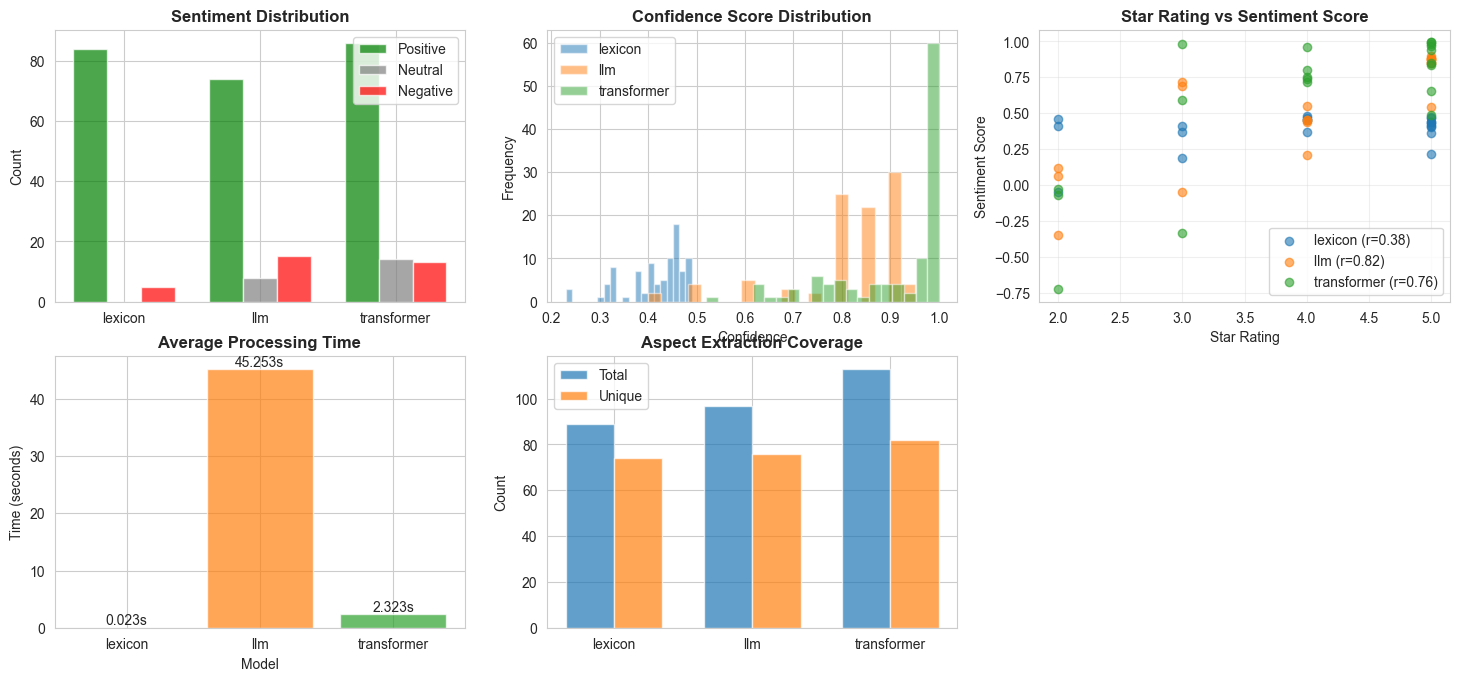

In [6]:
# ==============================================================================
# 7. PERFORMANCE COMPARISON
# ==============================================================================

print("\n" + "=" * 80)
print("PERFORMANCE COMPARISON")
print("=" * 80)

perf_summary = pd.DataFrame({
    'Model': active_models,
    'Avg Time (s)': [stats[m]['avg_time'] for m in active_models],
    'Total Time (s)': [stats[m]['total_time'] for m in active_models],
    'Aspects/Review': [stats[m]['avg_aspects_per_review'] for m in active_models],
    'Avg Confidence': [stats[m]['avg_confidence'] for m in active_models],
    'Throughput (rev/s)': [1/stats[m]['avg_time'] if stats[m]['avg_time'] > 0 else 0 for m in active_models]
})

print("\n" + perf_summary.to_string(index=False))

# ==============================================================================
# 8. VISUALIZATIONS
# ==============================================================================

print("\n" + "=" * 80)
print("GENERATING VISUALIZATIONS")
print("=" * 80)

sns.set_style("whitegrid")
fig = plt.figure(figsize=(18, 12))

# 3. Sentiment Distribution
ax3 = plt.subplot(3, 3, 1)
sent_data = []
for model in active_models:
    dist = stats[model]['sentiment_dist']
    sent_data.append([dist.get('positive', 0), dist.get('neutral', 0), dist.get('negative', 0)])

x = np.arange(len(active_models))
width = 0.25
ax3.bar(x - width, [d[0] for d in sent_data], width, label='Positive', color='green', alpha=0.7)
ax3.bar(x, [d[1] for d in sent_data], width, label='Neutral', color='gray', alpha=0.7)
ax3.bar(x + width, [d[2] for d in sent_data], width, label='Negative', color='red', alpha=0.7)
ax3.set_title('Sentiment Distribution', fontweight='bold')
ax3.set_ylabel('Count')
ax3.set_xticks(x)
ax3.set_xticklabels(active_models)
ax3.legend()

# 4. Confidence Distribution
ax4 = plt.subplot(3, 3, 2)
for model in active_models:
    confidences = []
    for result in all_results[model]:
        confidences.extend([p.confidence for p in result['predictions']])
    if confidences:
        ax4.hist(confidences, alpha=0.5, bins=20, label=model)
ax4.set_title('Confidence Score Distribution', fontweight='bold')
ax4.set_xlabel('Confidence')
ax4.set_ylabel('Frequency')
ax4.legend()

# 5. Star Rating vs Sentiment Score
ax5 = plt.subplot(3, 3, 3)
for model in active_models:
    if model in correlation_data:
        ax5.scatter(correlation_data[model]['stars'],
                   correlation_data[model]['scores'],
                   alpha=0.6, label=f"{model} (r={correlation_data[model]['correlation']:.2f})")
ax5.set_title('Star Rating vs Sentiment Score', fontweight='bold')
ax5.set_xlabel('Star Rating')
ax5.set_ylabel('Sentiment Score')
ax5.legend()
ax5.grid(alpha=0.3)

# 6. Processing Speed Comparison
ax6 = plt.subplot(3, 3, 4)
speeds = [stats[m]['avg_time'] for m in active_models]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'][:len(active_models)]
ax6.bar(active_models, speeds, color=colors, alpha=0.7)
ax6.set_title('Average Processing Time', fontweight='bold')
ax6.set_ylabel('Time (seconds)')
ax6.set_xlabel('Model')
for i, v in enumerate(speeds):
    ax6.text(i, v, f'{v:.3f}s', ha='center', va='bottom')

# 7. Unique vs Total Aspects
ax7 = plt.subplot(3, 3, 5)
total_aspects = [stats[m]['total_aspects'] for m in active_models]
unique_aspects = [stats[m]['unique_aspects'] for m in active_models]
x = np.arange(len(active_models))
width = 0.35
ax7.bar(x - width/2, total_aspects, width, label='Total', alpha=0.7)
ax7.bar(x + width/2, unique_aspects, width, label='Unique', alpha=0.7)
ax7.set_title('Aspect Extraction Coverage', fontweight='bold')
ax7.set_ylabel('Count')
ax7.set_xticks(x)
ax7.set_xticklabels(active_models)
ax7.legend()
